# 39 · Project 2: the three-layer cake: PDDL plan → IK waypoints → joint control on the Panda

In [1]:
import os, logging, mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt
from pyperplan.planner import search_plan, SEARCHES, HEURISTICS
from vlacourse import add_ee_site, solve_ik, yaw_quat, show_video, torque_panda
from vlacourse.tabletop import lookat_xyaxes

logging.disable(logging.CRITICAL)
H = 0.02
BLOCKS = {"a": [0.9, 0.2, 0.2, 1], "b": [0.2, 0.7, 0.2, 1], "c": [0.2, 0.3, 0.9, 1], "d": [0.95, 0.8, 0.1, 1], "e": [0.6, 0.3, 0.8, 1]}
TABLE_SLOTS = [np.array([0.40, -0.2]), np.array([0.40, 0.2]), np.array([0.60, -0.25]), np.array([0.62, 0.25]), np.array([0.5, 0.0])]

def build_world():
    spec = mm.get("franka_emika_panda").spec("scene"); add_ee_site(spec)
    spec.geom("floor").pos = [0, 0, -0.75]
    wb = spec.worldbody
    wb.add_geom(name="table", type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.5, 0.65, 0.375], pos=[0.4, 0, -0.375], rgba=[0.55, 0.42, 0.3, 1])
    for k, rgba in BLOCKS.items():
        b = wb.add_body(name=k, pos=[0, 0, H]); b.add_freejoint(name=k)
        b.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[H] * 3, rgba=rgba, mass=0.05, friction=[1.5, 0.01, 0.001])
    wb.add_camera(name="front", pos=[1.1, 0.3, 0.7], xyaxes=lookat_xyaxes([1.1, 0.3, 0.7], [0.5, 0, 0.1]))
    spec.visual.global_.offwidth, spec.visual.global_.offheight = 1920, 1080   # allow HD renders for the showcase video
    m = spec.compile(); d = mujoco.MjData(m)
    return m, d

def set_towers(m, d, towers):
    mujoco.mj_resetDataKeyframe(m, d, 0)
    for (x, y), stack in towers:
        for level, k in enumerate(reversed(stack)):
            adr = m.jnt_qposadr[m.joint(k).id]
            d.qpos[adr:adr + 7] = [x, y, H + 2 * H * level, 1, 0, 0, 0]
    mujoco.mj_forward(m, d)

class Executor:
    def __init__(self, m, d, every=40, size=(300, 400)):
        self.m, self.d, self.q = m, d, d.qpos[:7].copy()
        self.frames, self.qlog, self.every = [], [], every
        self.r = mujoco.Renderer(m, *size)
        self.free_slots = [s for s in TABLE_SLOTS]

    def render(self):
        self.r.update_scene(self.d, "front"); return self.r.render()

    def move(self, pos, grip, T=0.8):
        q_goal, res = solve_ik(self.m, self.d, np.asarray(pos), yaw_quat(0.0), self.q)
        if res > 1e-3:
            raise RuntimeError(f"IK failed for {pos} (residual {res:.3g})")
        n = int(T / self.m.opt.timestep)
        for i in range(n):
            s = (i + 1) / n; s = 3 * s**2 - 2 * s**3
            self.d.ctrl[:7] = self.q + (q_goal - self.q) * s; self.d.ctrl[7] = grip
            mujoco.mj_step(self.m, self.d)
            self.qlog.append(self.d.qpos[:7].copy())
            if i % self.every == 0:
                self.frames.append(self.render())
        self.q = q_goal

    def grasp_at(self, p):
        self.move(p + [0, 0, 0.12], 255); self.move(p, 255); self.move(p, 0, 0.4); self.move(p + [0, 0, 0.15], 0)

    def release_at(self, p):
        self.move(p + [0, 0, 0.15], 0); self.move(p + [0, 0, 0.004], 0); self.move(p + [0, 0, 0.004], 255, 0.4); self.move(p + [0, 0, 0.15], 255)

    def block(self, k):
        return self.d.body(k).xpos.copy()

    def execute(self, op):
        name, *args = op.name.strip("()").split()
        if name in ("pick-up", "unstack"):
            self.grasp_at(self.block(args[0]))
        elif name == "stack":
            self.release_at(self.block(args[1]) + [0, 0, 2 * H])
        elif name == "put-down":
            slot = next(s for s in self.free_slots if all(np.linalg.norm(self.block(k)[:2] - s) > 0.06 for k in BLOCKS))
            self.release_at(np.r_[slot, H])

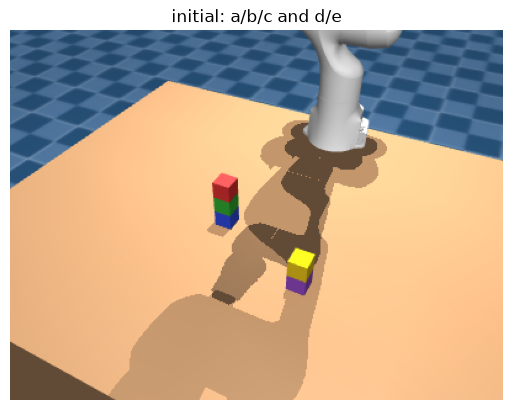

In [2]:
m, d = build_world()
set_towers(m, d, [((0.45, -0.1), ["a", "b", "c"]), ((0.55, 0.12), ["d", "e"])])
r = mujoco.Renderer(m, 300, 400); r.update_scene(d, "front")
plt.imshow(r.render()); plt.axis("off"); plt.title("initial: a/b/c and d/e"); plt.show()

In [3]:
os.makedirs("generated", exist_ok=True)
from importlib import import_module
DOMAIN = open("generated/blocksworld.pddl").read() if os.path.exists("generated/blocksworld.pddl") else None
assert DOMAIN, "run notebook 38 first (it writes generated/blocksworld.pddl)"
plan = search_plan("generated/blocksworld.pddl", "generated/problem_5.pddl", SEARCHES["astar"], HEURISTICS["hff"])
print([op.name for op in plan])

['(unstack a b)', '(put-down a)', '(unstack b c)', '(put-down b)', '(pick-up c)', '(stack c d)', '(pick-up b)', '(stack b c)', '(pick-up a)', '(stack a b)']


In [4]:
ex = Executor(m, d)
for i, op in enumerate(plan):
    ex.execute(op)
    print(f"{i + 1:2d}. {op.name:18s} done   ee={d.site('ee').xpos.round(3)}")
order = sorted(BLOCKS, key=lambda k: -d.body(k).xpos[2])
xy_spread = np.ptp(np.array([d.body(k).xpos[:2] for k in BLOCKS]), axis=0)
print("top-to-bottom order:", order, "| tower xy spread [mm]:", (xy_spread * 1000).round(1))
print("GOAL REACHED:", order == ["a", "b", "c", "d", "e"] and np.all(xy_spread < 0.02))

 1. (unstack a b)      done   ee=[ 0.449 -0.099  0.235]
 2. (put-down a)       done   ee=[ 0.399 -0.199  0.157]


 3. (unstack b c)      done   ee=[ 0.449 -0.099  0.195]
 4. (put-down b)       done   ee=[0.399 0.199 0.156]


 5. (pick-up c)        done   ee=[ 0.451 -0.099  0.16 ]
 6. (stack c d)        done   ee=[0.549 0.121 0.235]


 7. (pick-up b)        done   ee=[0.404 0.2   0.167]
 8. (stack b c)        done   ee=[0.551 0.116 0.276]


 9. (pick-up a)        done   ee=[ 0.402 -0.201  0.166]
10. (stack a b)        done   ee=[0.55  0.116 0.31 ]
top-to-bottom order: ['a', 'b', 'c', 'd', 'e'] | tower xy spread [mm]: [ 6.3 18. ]
GOAL REACHED: True


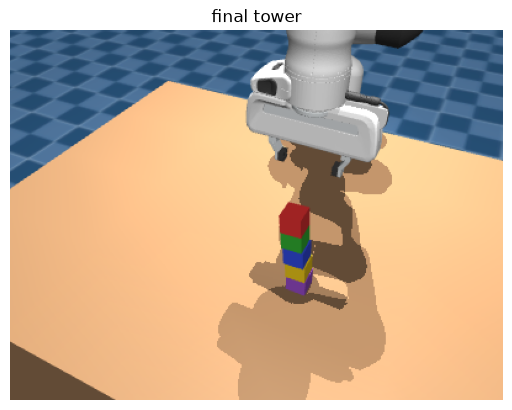

In [5]:
show_video(ex.frames, fps=25, title="PDDL plan executed")
plt.imshow(ex.frames[-1]); plt.axis("off"); plt.title("final tower"); plt.show()

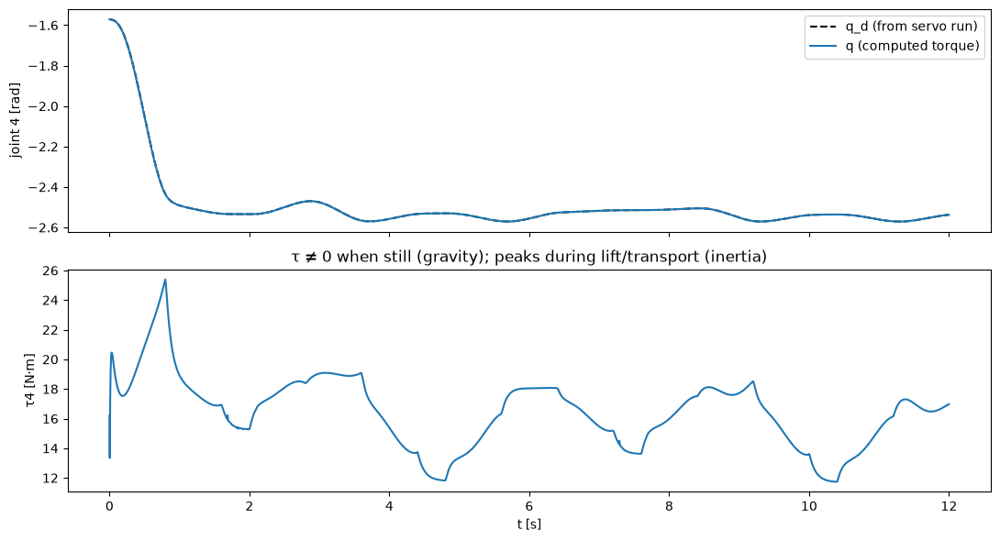

computed-torque replay: RMS joint error 0.044 deg


In [6]:
Q = np.array(ex.qlog)
dt = m.opt.timestep
Qd, Qdd = np.gradient(Q, dt, axis=0), np.gradient(np.gradient(Q, dt, axis=0), dt, axis=0)
tm, td = torque_panda()
td.qpos[:7] = Q[0]; mujoco.mj_forward(tm, td)
taus, qs = [], []
for i in range(0, min(len(Q), 6000)):
    td.qacc[:] = 0
    td.qacc[:7] = Qdd[i] + 100 * (Q[i] - td.qpos[:7]) + 20 * (Qd[i] - td.qvel[:7])
    ff = td.qacc.copy(); mujoco.mj_inverse(tm, td)
    tau = td.qfrc_inverse[:7].copy()
    td.ctrl[:7] = tau; td.ctrl[7] = 255
    mujoco.mj_step(tm, td)
    taus.append(tau); qs.append(td.qpos[:7].copy())
taus, qs = np.array(taus), np.array(qs)
t = np.arange(len(qs)) * dt
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(t, Q[:len(qs), 3], "k--", label="q_d (from servo run)"); ax[0].plot(t, qs[:, 3], label="q (computed torque)"); ax[0].set_ylabel("joint 4 [rad]"); ax[0].legend()
ax[1].plot(t, taus[:, 3]); ax[1].set_ylabel("τ4 [N·m]"); ax[1].set_xlabel("t [s]")
ax[1].set_title("τ ≠ 0 when still (gravity); peaks during lift/transport (inertia)"); plt.tight_layout(); plt.show()
print(f"computed-torque replay: RMS joint error {np.degrees(np.sqrt(np.mean((qs - Q[:len(qs)]) ** 2))):.3f} deg")

## Showcase video (for LinkedIn, slides, your portfolio)
Same plan, re-executed with an HD orbiting camera. The symbolic plan runs in a side panel: done steps get a tick,
the active step is highlighted. Real time (500 Hz physics, one frame every 20 steps = 25 fps), 1280x720, H.264.

saved outputs/39_pddl_to_torque_showcase.mp4  (13.6 MB)


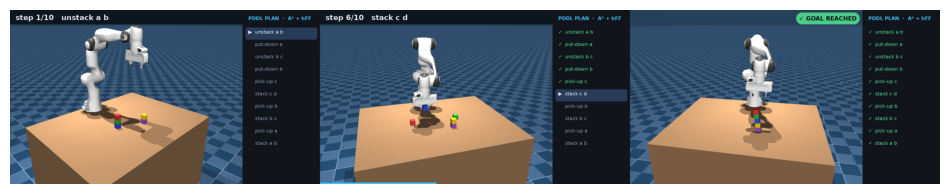

In [7]:
from vlacourse import showcase as sc

class ShowcaseExecutor(Executor):
    """Executor that renders an HD orbiting view and remembers which plan step each frame belongs to."""
    def __init__(self, m, d):
        super().__init__(m, d, every=20, size=(720, 960))
        self.cam = mujoco.MjvCamera()
        self.cam.lookat[:] = [0.45, 0.0, 0.25]; self.cam.distance, self.cam.elevation = 1.75, -20
        self.op, self.tags = 0, []

    def render(self):
        self.cam.azimuth = 135 + 0.08 * len(self.frames)        # slow orbit around the table
        self.r.update_scene(self.d, self.cam); self.tags.append(self.op)
        return self.r.render()

m, d = build_world()
set_towers(m, d, [((0.45, -0.1), ["a", "b", "c"]), ((0.55, 0.12), ["d", "e"])])
sx = ShowcaseExecutor(m, d)
for i, op in enumerate(plan):
    sx.op = i; sx.execute(op)
order = sorted(BLOCKS, key=lambda k: -d.body(k).xpos[2])
ok = order == ["a", "b", "c", "d", "e"] and np.all(np.ptp(np.array([d.body(k).xpos[:2] for k in BLOCKS]), axis=0) < 0.02)

steps = [op.name.strip("()") for op in plan]
video = sc.title_card("From symbols to torques", "PDDL plan  →  IK waypoints  →  joint control\nFranka Panda in MuJoCo",
                      size=(720, 1280), n=60)
for k, (f, i) in enumerate(zip(sx.frames, sx.tags)):
    f = sc.progress(sc.caption(f, f"step {i + 1}/{len(steps)}   {steps[i]}", where="top"), (k + 1) / len(sx.frames))
    video.append(np.hstack([f, sc.side_panel(steps, i, size=(720, 320), header="PDDL PLAN  ·  A* + hFF")]))
end = sc.badge(sx.frames[-1], "✓ GOAL REACHED" if ok else "goal NOT reached", color=sc.GOOD if ok else (240, 90, 90))
video += [np.hstack([end, sc.side_panel(steps, len(steps), size=(720, 320), header="PDDL PLAN  ·  A* + hFF")])] * 50
video += sc.title_card("The classical stack", "planner + IK + control: no learning, no data\nthe baseline every VLA is measured against", size=(720, 1280), n=50)
show_video(video, fps=25, title="showcase")
sc.export(video, "outputs/39_pddl_to_torque_showcase.mp4", fps=25)
plt.figure(figsize=(12, 3.6)); plt.imshow(np.hstack([video[60], video[60 + len(sx.frames) // 2], video[-60]])); plt.axis("off"); plt.show()